# Доп. Задание для КТвД

**Исследование датасета дизайнерских постеров** [Enhanced Poster Design Dataset, v2](https://www.kaggle.com/datasets/ziya07/enhanced-poster-design-dataset)

**Содержание:**
- [1. Данные](#scrollTo=c75bfa18&line=4&uniqifier=1)
- [2. Математическая модель](#scrollTo=1f2a8085&line=11&uniqifier=1)
- [3. EDA](#scrollTo=34884f19&line=2&uniqifier=1)
- [4. Зависимость](#scrollTo=81a3a736&line=12&uniqifier=1)
- [5. Генератор](#scrollTo=56b1d29e&line=4&uniqifier=1)
- [6. Выводы](#scrollTo=9858b438&line=4&uniqifier=1)


## Датасет

Рассматриваем каждый постер. Поле Colors содержит список используемых в нём цветовых кодов.

In [3]:

import ast
from pathlib import Path

import sys
sys.path.append('/content')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import chi2_contingency
from poster_style import plot_joint, plot_marginals

# Загрузка датасета
import kagglehub

csv_path = Path(kagglehub.dataset_download(
    "ziya07/enhanced-poster-design-dataset",
    path="enhanced_poster_design_dataset.csv"
))

# Подготовка данных
df = pd.read_csv(csv_path)

missing = int(df.isna().sum().sum())
duplicates = int(df.duplicated().sum())

colors = df["Colors"].map(ast.literal_eval)
df["X"] = colors.map(len)
df["Y"] = colors.map(lambda c: len(set(c)))

X, Y, N = df["X"], df["Y"], len(df)

assert (Y <= X).all()

print(
    f"Кол-во постеров: {N:,} | "
    f"исходных признаков: {df.shape[1]-2} | "
    f"пропусков: {missing} | "
    f"дублей: {duplicates}"
)


Using Colab cache for faster access to the 'enhanced-poster-design-dataset' dataset.
Кол-во постеров: 10,000 | исходных признаков: 15 | пропусков: 0 | дублей: 0


Скорее всего датасет синтетический, т.к. данных ровно 10000 и нет повторов, пустот и странных значений


## Математическая модель

Выбираем один постер **равновероятно** из $N$ строк. Введём вероятностное пространство:

$$
\Omega=\{1,\ldots,N\},\quad \mathcal F=2^\Omega,\quad
\mathbb P(A)=\frac{|A|}{N},\quad A\subseteq\Omega.
$$

Пусть $C_i$ - список цветов $i$-го постера. Рассмотрим две дискретные случайные величины:

$$
X(i)=|C_i|,\qquad Y(i)=|\operatorname{set}(C_i)|.
$$

**Почему это случайные величины:** $X,Y:\Omega\to\mathbb R$. Для любого борелевского $B\subseteq\mathbb R$ прообразы $X^{-1}(B)$ и $Y^{-1}(B)$ являются подмножествами конечного $\Omega$, а значит принадлежат $\mathcal F$. Следовательно, обе функции измеримы.

Эмпирические вероятности и характеристики:

$$
\widehat p_X(x)=\frac{\#\{i:X(i)=x\}}{N},\quad
\mathbb E[Z]=\sum_z z\widehat p_Z(z),\quad
\operatorname{Var}(Z)=\sum_z(z-\mathbb E[Z])^2\widehat p_Z(z).
$$


## EDA

### Распределения и числовые характеристики

In [4]:
pmf = pd.DataFrame({
    "P(X=x)": X.value_counts(normalize=True),
    "P(Y=y)": Y.value_counts(normalize=True),
}).sort_index().fillna(0)
summary = pd.DataFrame({
    "Среднее, шт.": [X.mean(), Y.mean()],
    "Дисперсия, шт.²": [X.var(ddof=0), Y.var(ddof=0)],
    "СКО, шт.": [X.std(ddof=0), Y.std(ddof=0)],
    "Медиана, шт.": [X.median(), Y.median()],
}, index=["X", "Y"])
display(pmf.round(4), summary.round(4))

,P(X=x),P(Y=y)
2,0.0000,0.0761
3,0.2452,0.3393
4,0.2505,0.3639
5,0.2415,0.2029
6,0.2628,0.0178


,"Среднее, шт.","Дисперсия, шт.²","СКО, шт.","Медиана, шт."
X,4.5219,1.2655,1.125,5.0
Y,3.7470,0.8538,0.924,4.0


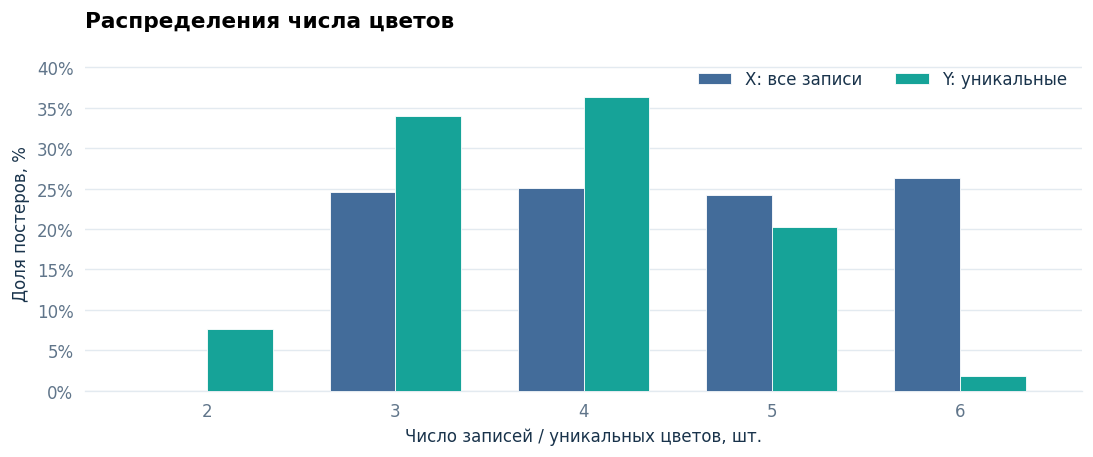

In [5]:
fig = plot_marginals(pmf)
display(fig)
plt.close(fig)

### Совместное и условное распределения

$$
\widehat p_{X,Y}(x,y)=\frac{\#\{i:X(i)=x,\,Y(i)=y\}}{N},\qquad
\widehat p_{Y\mid X}(y\mid x)=\frac{\widehat p_{X,Y}(x,y)}{\widehat p_X(x)}.
$$

На графиках ниже **одна цветовая шкала** и проценты от числа постеров. Поэтому реальные частоты можно непосредственно сравнить с моделью независимости.

In [6]:
freq = pd.crosstab(X, Y)
joint = freq / N
conditional = freq.div(freq.sum(axis=1), axis=0)
display(conditional.round(3))

Y,2,3,4,5,6
X,,,,,
3,0.274,0.726,0.000,0.000,0.000
4,0.035,0.484,0.481,0.000,0.000
5,0.000,0.153,0.593,0.254,0.000
6,0.000,0.013,0.381,0.538,0.068


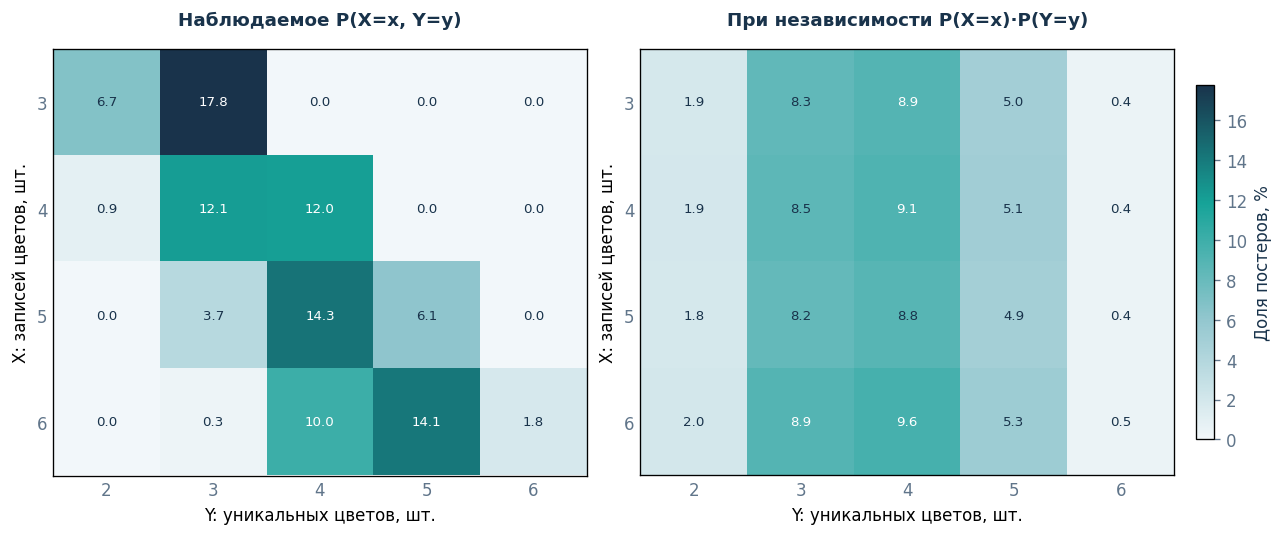

In [7]:
fig = plot_joint(joint)
display(fig)
plt.close(fig)


## Доказательство зависимости

Для любого постера $Y\le X$. В датасете встречаются $X=3$ и $Y=6$, но их совместное появление невозможно:

$$
\widehat{P}(X=3,Y=6)=0,\qquad
\widehat{P}(X=3)\widehat{P}(Y=6)
=0.2452\cdot 0.0178=0.00436456>0.
$$

Таким образом, **$X$ и $Y$ зависимы**: равенство произведения маргинальных и совместной вероятностей нарушено.

Для дополнительной проверки используем критерий $\chi^2$:

$$
H_0:X\perp Y,\quad
E_{xy}=N\widehat p_X(x)\widehat p_Y(y),\quad
\chi^2=\sum_{x,y}\frac{(O_{xy}-E_{xy})^2}{E_{xy}}.
$$

In [8]:
p_x3 = (X == 3).mean()
p_y6 = (Y == 6).mean()
p_joint = ((X == 3) & (Y == 6)).mean()
assert p_joint == 0 < p_x3 * p_y6
chi2, p_value, dof, expected = chi2_contingency(freq, correction=False)
v = np.sqrt(chi2 / (N * min(freq.shape[0] - 1, freq.shape[1] - 1)))
print(f"P(X=3,Y=6)={p_joint:.6f}; P(X=3)P(Y=6)={p_x3*p_y6:.8f}")
print(f"χ²={chi2:.1f}; df={dof}; p={'< 1e-300' if p_value == 0 else f'{p_value:.2g}'}; "
      f"min(E)={expected.min():.1f}; V Крамера={v:.3f}")

P(X=3,Y=6)=0.000000; P(X=3)P(Y=6)=0.00436456
χ²=8345.4; df=12; p=< 1e-300; min(E)=43.0; V Крамера=0.527



## Интерактивный генератор marimo

Как запустить:

```bash
pip install marimo kagglehub pandas numpy scipy matplotlib
py -m marimo run poster_marimo.py
```

В приложении можно менять **число испытаний**, **seed** и **модель генерации**. Совместная модель берёт реальные пары $(X,Y)$; независимая моделирует $H_0$ и может создавать невозможные пары $Y>X$.


## Выводы

1. В датасете 10 000 постеров без пропусков и полных дублей. В 62,2% записей цветовые коды повторяются, а значит дизайнеры используют одинаковые оттенки, возможно из готовых палитр.
2. В среднем в постере **4,52** записей цветов и **3,75** различных цветов. Наиболее частое значение $Y$ — 4. Действительно, наилучшими решениями в дизайне обычно выступают ограниченные цветовые палитры. Такое кол-во цветов будет комфортно для восприятия человеческим глазом.
3. В выбранной модели величины зависимы: $\widehat P(X=3,Y=6)=0$, но $\widehat P(X=3)\widehat P(Y=6)>0$. Критерий $\chi^2$ подтверждает существенное расхождение с независимостью ($V=0.527$).
4. При искусственном независимом выборе около 20,3% пар нарушают $Y\le X$. Для реалистичного генератора следует выбирать совместную модель.